# 🏦 Loan Approval Predictor: Decision Tree (Improved)

**Goal:** Predict whether a home loan application will be **approved** or **rejected**, and make the model more useful for a lender by testing two improvements.

**Problem type:** Binary classification (0 = rejected, 1 = approved)

**Dataset:** Loan Prediction dataset, about 600 loan applications from a housing finance company

**What this notebook does**
1. Builds a basic decision tree and shows how deeper trees **overfit**
2. Tests two improvements: **new features** (total income, monthly instalment, instalment-to-income ratio) and **class weights** (making a wrongly approved loan count more)
3. Compares all combinations with repeated cross-validation and picks the best
4. Exports the final tree to a website that shows the exact questions it asked

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn

> This is an educational project. It must not be used to make real lending decisions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     StratifiedKFold, RepeatedStratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score, precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)

sns.set_style("whitegrid")
RANDOM_STATE = 42

# Gender and Married are NOT used as model features (see the fairness note in section 2)
BASE_NUM = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
NEW_NUM = ["TotalIncome", "EMI", "EMI_to_Income"]
EXT_NUM = BASE_NUM + NEW_NUM
CAT_COLS = ["Dependents", "Education", "Self_Employed", "Credit_History", "Property_Area"]

## 1. Load the Data

| Column | Meaning |
|---|---|
| Gender, Married | Applicant's gender and marital status |
| Dependents | Number of dependents (0, 1, 2, or 3+) |
| Education | Graduate or Not Graduate |
| Self_Employed | Whether the applicant is self-employed |
| ApplicantIncome, CoapplicantIncome | Monthly income of the applicant and the co-applicant |
| LoanAmount | Loan amount, in thousands |
| Loan_Amount_Term | Loan term, in months |
| Credit_History | Whether the credit history meets guidelines (1) or not (0) |
| Property_Area | Urban, Semiurban, or Rural |
| Loan_Status | **Target:** Y = approved, N = rejected |

In [2]:
# The same public file (train_u6lujuX_CVtuZ9i.csv) from different GitHub repositories.
# The code tries them one by one until one works.
URLS = [
    "https://raw.githubusercontent.com/keithkamson/loan-prediction-ML/main/train_u6lujuX_CVtuZ9i.csv",
    "https://raw.githubusercontent.com/ShubhamKumar2202/loan-prediction/main/train_u6lujuX_CVtuZ9i.csv",
]

df = None
for url in URLS:
    try:
        candidate = pd.read_csv(url)
        if "Loan_Status" in candidate.columns:
            df = candidate
            print("Loaded from:", url)
            break
    except Exception:
        print("Could not load from:", url)

if df is None:
    # If every download fails, upload the CSV file by hand
    print("\nDownload failed. Please choose train_u6lujuX_CVtuZ9i.csv from your computer.")
    print("(It is on Kaggle: search for 'Loan Prediction Problem Dataset'.)")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

# Some copies of the file name this column differently
df = df.rename(columns={"Self_Employment": "Self_Employed"})

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Loaded from: https://raw.githubusercontent.com/keithkamson/loan-prediction-ML/main/train_u6lujuX_CVtuZ9i.csv
Shape: (614, 13)
Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
needed = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "ApplicantIncome",
          "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History",
          "Property_Area", "Loan_Status"]
missing_cols = [c for c in needed if c not in df.columns]
assert not missing_cols, f"These columns are missing: {missing_cols}. Check the column names printed above."

print("Missing values per column:")
print(df[needed].isnull().sum()[df[needed].isnull().sum() > 0])
df[needed].describe().T

Missing values per column:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


## 2. Data Cleaning and New Features

Changes made:
- Turn `Loan_Status` into a number: 1 = approved, 0 = rejected
- Turn `Credit_History` into readable labels: **Good** (1), **Poor** (0), or **Unknown** (missing). A missing credit history is kept as its own group instead of guessing a value
- Other missing values are filled **inside the model pipeline** (median for numbers, most common value for categories), so the test data never influences the filling
- No outlier removal is needed, because decision trees split on thresholds and are not affected by extreme values

**New features** (calculated from each application, so no information leaks between train and test):
- `TotalIncome` = applicant income + co-applicant income
- `EMI` = the monthly instalment, estimated as loan amount ÷ term (the loan amount is in thousands, so it is multiplied by 1,000)
- `EMI_to_Income` = the share of the household's monthly income needed for the instalment

**Fairness note:** `Gender` and `Married` are **not used as features**. A lending decision should not depend on them. They are still shown in the EDA, only to check whether approval rates differ.

In [4]:
df = df[needed].copy()

df["target"] = (df["Loan_Status"] == "Y").astype(int)
df["Credit_History"] = df["Credit_History"].map({1.0: "Good", 0.0: "Poor"}).fillna("Unknown")

# New features
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["EMI"] = df["LoanAmount"] * 1000 / df["Loan_Amount_Term"]
df["EMI_to_Income"] = df["EMI"] / df["TotalIncome"]

print("Rows:", len(df))
print(df["Credit_History"].value_counts())
df[["ApplicantIncome", "CoapplicantIncome", "TotalIncome", "LoanAmount", "EMI", "EMI_to_Income"]].head()

Rows: 614
Credit_History
Good       475
Poor        89
Unknown     50
Name: count, dtype: int64


,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,EMI,EMI_to_Income
0,5849,0.0,5849.0,NaN,NaN,NaN
1,4583,1508.0,6091.0,128.0,355.555556,0.058374
2,3000,0.0,3000.0,66.0,183.333333,0.061111
3,2583,2358.0,4941.0,120.0,333.333333,0.067463
4,6000,0.0,6000.0,141.0,391.666667,0.065278


## 3. Exploratory Data Analysis (EDA)

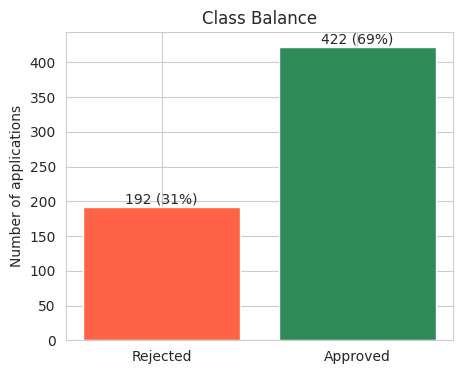

In [5]:
counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["Rejected", "Approved"], counts.values, color=["tomato", "seagreen"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, f"{v} ({v / len(df) * 100:.0f}%)", ha="center")
plt.ylabel("Number of applications")
plt.title("Class Balance")
plt.show()

**Insight:** About two thirds of the applications are approved. A model that always predicts "approved" would already be right about that often, so this is the **baseline** to beat. Because the classes are unbalanced, accuracy alone can hide how many rejected applications the model misses.

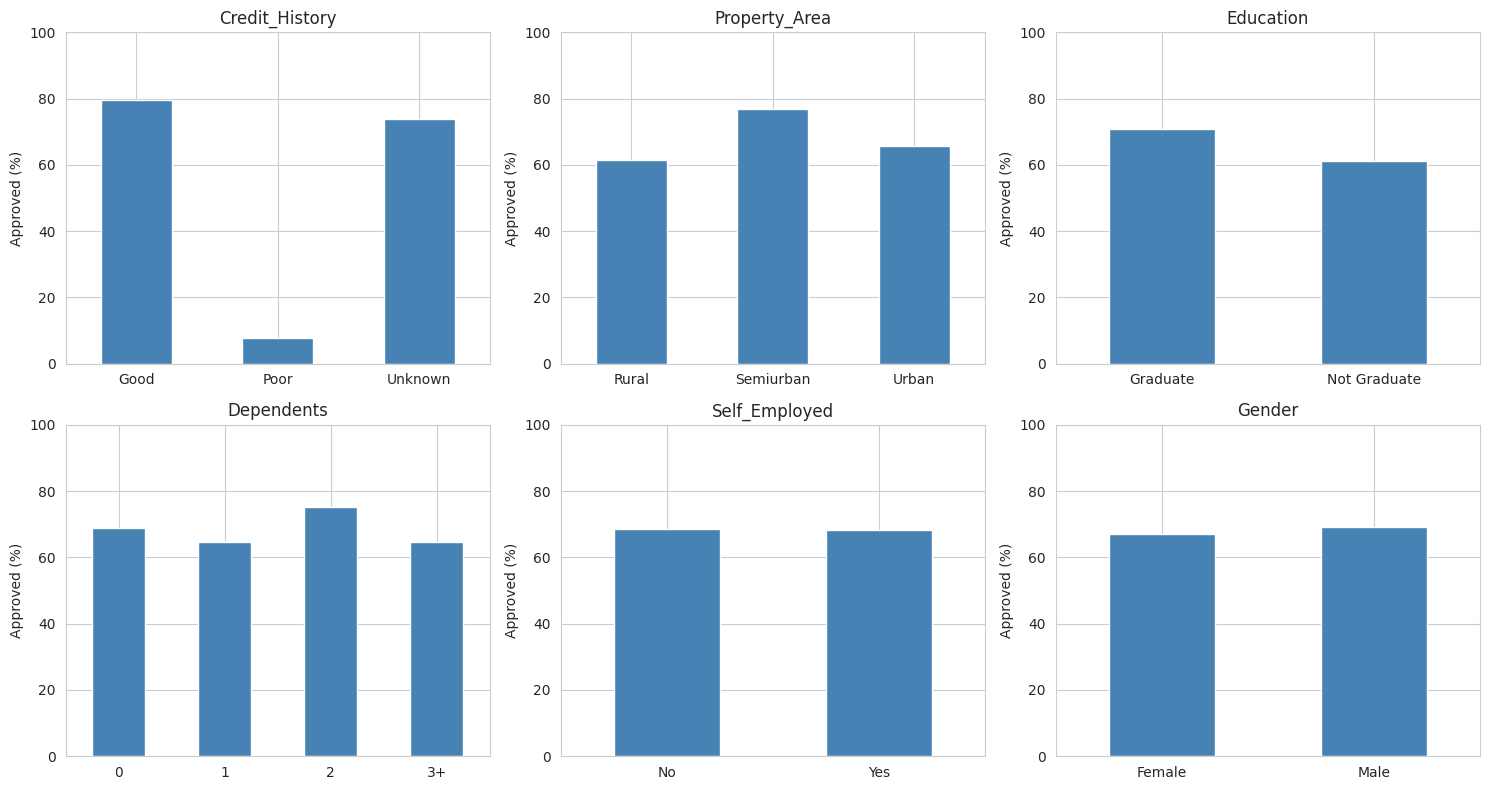

In [6]:
cat_to_plot = ["Credit_History", "Property_Area", "Education", "Dependents", "Self_Employed", "Gender"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_to_plot):
    rate = df.groupby(col)["target"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_ylabel("Approved (%)")
    ax.set_xlabel("")
    ax.set_title(col)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Credit history is by far the strongest signal: about 80% of applicants with a good credit history were approved, compared with only about 8% of those with a poor one. Applicants with an unknown (missing) credit history were approved about 74% of the time, close to the good group. Semiurban areas (about 77%) and graduates (about 71%) have higher approval rates than rural areas (about 61%) and non-graduates (about 61%). Approval rates for women and men are almost equal (about 67% and 69%), and gender is not used by the model.

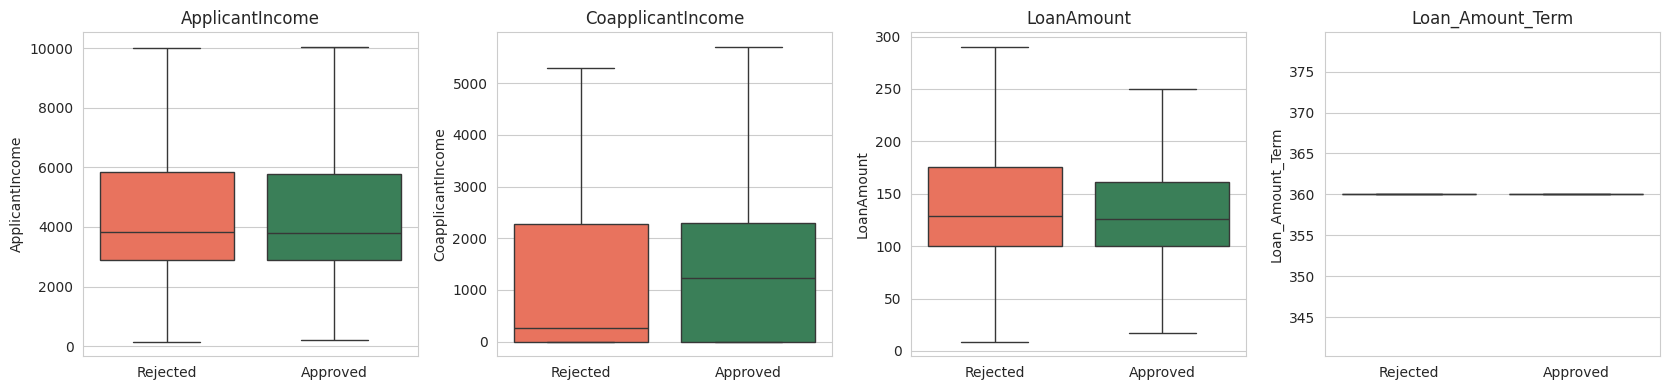

In [7]:
def boxplots(cols):
    fig, axes = plt.subplots(1, len(cols), figsize=(4.2 * len(cols), 4))
    for ax, col in zip(axes, cols):
        sns.boxplot(x="target", y=col, data=df, ax=ax, hue="target", palette=["tomato", "seagreen"],
                    legend=False, showfliers=False)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Rejected", "Approved"])
        ax.set_xlabel("")
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

boxplots(BASE_NUM)

**Insight:** Applicant income is almost the same for approved and rejected applications. Approved applications tend to have a higher co-applicant income (median about 1,200, against about 250 for rejected ones). Rejected applications show somewhat larger loan amounts at the upper end. `Loan_Amount_Term` is 360 months for almost everyone, so it carries very little information.

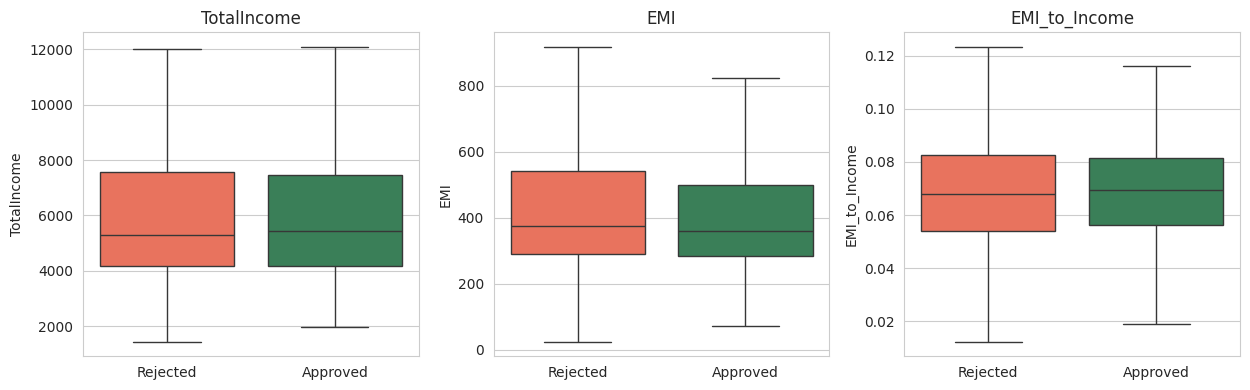

In [8]:
boxplots(NEW_NUM)

**Insight:** The three new features overlap heavily between approved and rejected applications. EMI is slightly lower for approved ones, but total income and the instalment-to-income ratio look almost the same in both groups. Whether they help the model is tested in section 7, using cross-validation.

## 4. Train/Test Split

`stratify=y` keeps the same share of approved applications in both sets. The dataset is small, so the test set holds only about 120 applications, and one application is worth almost one percentage point of accuracy. Test results can be noisy, which is why model choices are made with **cross-validation on the training set** and the test set is used only once at the end.

In [9]:
X = df[EXT_NUM + CAT_COLS]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Approved share in train: %.2f | in test: %.2f" % (y_train.mean(), y_test.mean()))

Train: (491, 12) | Test: (123, 12)
Approved share in train: 0.69 | in test: 0.69


## 5. How a Decision Tree Works

A decision tree asks a series of yes/no questions about the data, like a flowchart. Each question splits the applications into two groups, and the tree picks the question that separates "approved" from "rejected" best. For example: *"Is the credit history Poor?"* At the end of each path (a **leaf**), the tree predicts the most common outcome among the training applications that ended up there.

**Depth** is the number of questions in a row. A shallow tree is simple but may miss patterns. A very deep tree can memorize the training data, including noise, and then do worse on new data. This is **overfitting**.

The pipeline:
1. **Numbers** have missing values filled with the median (no scaling is needed for trees).
2. **Categories** have missing values filled with the most common value, then are converted to 0/1 columns with `OneHotEncoder`.
3. **DecisionTreeClassifier** learns the questions. `min_samples_leaf=5` means every leaf must contain at least 5 applications.

**Class weights:** by default, every application counts the same. With `class_weight="balanced"`, the rarer class (rejected applications) counts more, so the tree works harder to catch them. This makes the tree more cautious.

In [10]:
def make_model(max_depth, class_weight=None, num_cols=BASE_NUM):
    preprocess = ColumnTransformer(
        [
            ("num", make_pipeline(SimpleImputer(strategy="median")), num_cols),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CAT_COLS),
        ],
        sparse_threshold=0,
    )
    tree = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=5,
                                  class_weight=class_weight, random_state=RANDOM_STATE)
    return make_pipeline(preprocess, tree)


# Baseline: always predict the most common class
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline accuracy (always predict approved): {baseline_acc:.3f}")

Baseline accuracy (always predict approved): 0.691


## 6. Step 1: How Deep Should the Tree Be?

First, the basic setup: the original features and no class weights. I try several depths and compare:
- **Train accuracy** vs **Test accuracy**, to detect overfitting
- **5-fold cross-validated accuracy** on the training set, a more reliable estimate than one split

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    model = make_model(depth)
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    rows.append({
        "Max depth": "None (full)" if depth is None else depth,
        "Leaves": model.named_steps["decisiontreeclassifier"].get_n_leaves(),
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "CV accuracy": cv_acc.mean(),
        "Test accuracy": accuracy_score(y_test, model.predict(X_test)),
    })

depth_results = pd.DataFrame(rows)
depth_results.round(3)

,Max depth,Leaves,Train accuracy,CV accuracy,Test accuracy
0,1,2,0.798,0.798,0.854
1,2,4,0.798,0.788,0.854
2,3,8,0.798,0.774,0.854
3,4,13,0.817,0.754,0.821
4,5,18,0.825,0.745,0.821
5,6,25,0.829,0.741,0.813
6,8,39,0.841,0.731,0.756
7,10,47,0.855,0.713,0.756
8,None (full),52,0.857,0.709,0.764


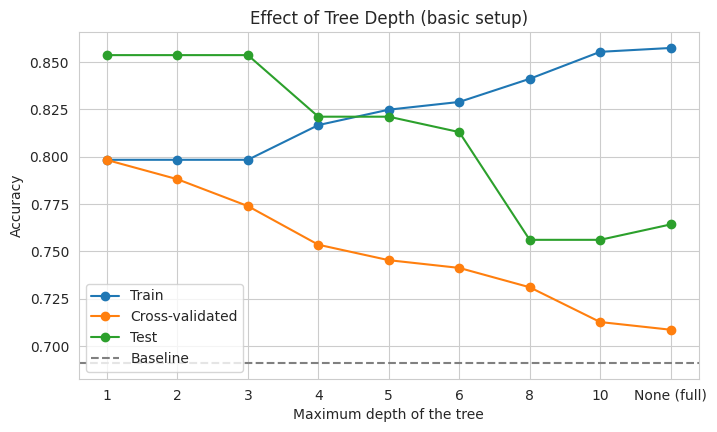

In [12]:
plot_df = depth_results.copy()
plot_df["x"] = range(len(plot_df))

plt.figure(figsize=(8, 4.5))
plt.plot(plot_df["x"], plot_df["Train accuracy"], marker="o", label="Train")
plt.plot(plot_df["x"], plot_df["CV accuracy"], marker="o", label="Cross-validated")
plt.plot(plot_df["x"], plot_df["Test accuracy"], marker="o", label="Test")
plt.axhline(baseline_acc, color="gray", linestyle="--", label="Baseline")
plt.xticks(plot_df["x"], plot_df["Max depth"].astype(str))
plt.xlabel("Maximum depth of the tree")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth (basic setup)")
plt.legend()
plt.show()

**How to read this:** As the tree gets deeper, the train accuracy keeps rising, because the tree can memorize the training data. The lines that matter are the cross-validated and test accuracy. When they stop rising or start falling while the train accuracy keeps climbing, the tree is overfitting.

**Result:** The simplest tree won. Depth 1 (a single question) had the best cross-validated accuracy (0.798). Deeper trees fit the training data better (train accuracy rises from 0.798 to 0.857) but do worse on new data: the cross-validated accuracy falls to 0.709 for the full tree, which has 52 leaves. This is overfitting. The test accuracy of the depth-1 tree (0.854) is higher than its cross-validated accuracy, which is most likely luck from the small test set (123 applications), so about 0.80 is the more reliable estimate.

The depth-1 tree asks only one thing: is the credit history Poor? That is a useful reference point, and the next step asks whether the improvements can beat it.

## 7. Step 2: Can New Features and Class Weights Help?

Accuracy hides an important problem here: a tree that approves almost everyone with an acceptable credit history reaches a good accuracy, but lets many **bad loans** through. For a lender, wrongly approving a loan that should have been rejected is usually the costlier mistake.

So this step compares all combinations of:
- **Features:** original features vs. original + the 3 new features
- **Class weight:** none vs. balanced
- **Depth:** 1 to 5

using **5-fold cross-validation repeated 3 times** (15 scores per setup, so the numbers are more stable). Besides accuracy, three more measures are reported:
- **Balanced accuracy:** the average of the share of approved applications found and the share of rejected applications found. It treats both groups equally, even though there are fewer rejected ones
- **Rejected caught (recall):** of the applications that should be rejected, how many the model rejects
- **Approved found (recall):** of the applications that should be approved, how many the model approves

In [13]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "recall_rejected": make_scorer(recall_score, pos_label=0),
    "recall_approved": make_scorer(recall_score, pos_label=1),
}

feature_sets = {"Original": BASE_NUM, "With new features": EXT_NUM}
weights = {"none": None, "balanced": "balanced"}

rows = []
for fs_name, num_cols in feature_sets.items():
    for w_name, w in weights.items():
        for depth in [1, 2, 3, 4, 5]:
            model = make_model(depth, class_weight=w, num_cols=num_cols)
            s = cross_validate(model, X_train, y_train, cv=rcv, scoring=scoring, n_jobs=-1)
            rows.append({
                "Features": fs_name,
                "Class weight": w_name,
                "Max depth": depth,
                "CV accuracy": s["test_accuracy"].mean(),
                "CV balanced accuracy": s["test_balanced_accuracy"].mean(),
                "Rejected caught": s["test_recall_rejected"].mean(),
                "Approved found": s["test_recall_approved"].mean(),
            })

grid = pd.DataFrame(rows)
grid["_bal"] = grid["CV balanced accuracy"].round(3)
grid = grid.sort_values(["_bal", "Max depth"], ascending=[False, True]).drop(columns="_bal").reset_index(drop=True)
grid.round(3)

,Features,Class weight,Max depth,CV accuracy,CV balanced accuracy,Rejected caught,Approved found
0,Original,none,1,0.798,0.689,0.396,0.982
1,Original,balanced,1,0.798,0.689,0.396,0.982
2,With new features,none,1,0.798,0.689,0.396,0.982
3,With new features,balanced,1,0.798,0.689,0.396,0.982
4,With new features,none,2,0.792,0.686,0.401,0.970
5,Original,none,2,0.791,0.684,0.396,0.971
6,With new features,none,3,0.780,0.671,0.377,0.964
7,Original,none,3,0.773,0.667,0.381,0.952
8,With new features,none,4,0.761,0.663,0.399,0.927
9,With new features,none,5,0.752,0.663,0.423,0.903


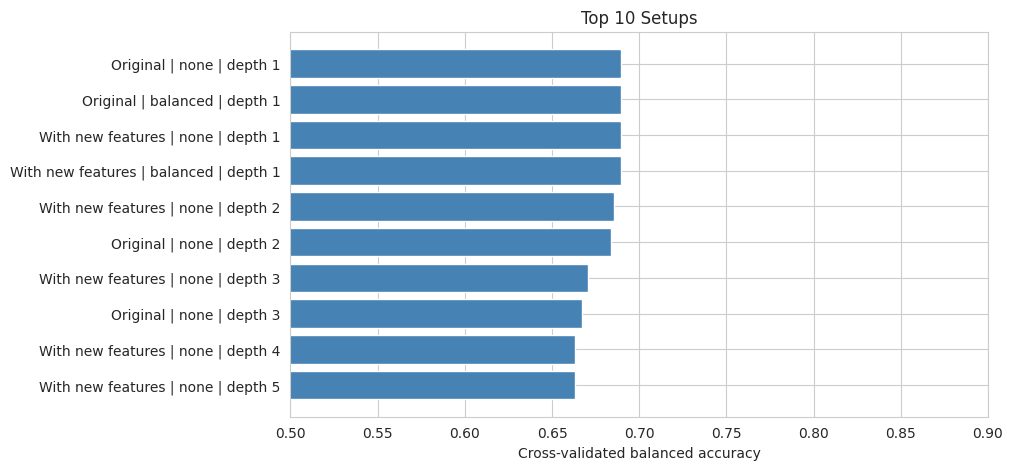

In [14]:
top = grid.head(10).copy()
top["label"] = top["Features"] + " | " + top["Class weight"] + " | depth " + top["Max depth"].astype(str)

plt.figure(figsize=(9, 5))
plt.barh(top["label"][::-1], top["CV balanced accuracy"][::-1], color="steelblue")
plt.xlabel("Cross-validated balanced accuracy")
plt.title("Top 10 Setups")
plt.xlim(0.5, max(0.9, top["CV balanced accuracy"].max() + 0.03))
plt.show()

**How to read this:** Each row is one setup, sorted by cross-validated balanced accuracy (when two setups tie, the simpler tree comes first). Compare the **Rejected caught** and **Approved found** columns: setups with class weights usually catch more rejected applications but also reject more good ones. Compare "Original" and "With new features" rows with the same class weight and depth to see whether the new features help.

**Insight:** The four depth-1 setups tie at the top (CV balanced accuracy 0.689, accuracy 0.798), with or without the new features and class weights, so the simplest one is chosen. The new features do not help: with them, the best deeper tree scores 0.686, slightly below the plain depth-1 tree. Class weights catch more rejected applications (up to 0.535, against about 0.40) but approve fewer good ones (as low as 0.743, against 0.98), so balanced accuracy falls for every weighted setup.

## 8. Pick the Best Setup and Evaluate It on the Test Set

The best setup is chosen using the cross-validation results above, not the test set. Then the test set is used **once**, to compare:
1. the **baseline** (always approve),
2. the **credit-history rule** (the basic depth-1 tree from step 1), and
3. the **best setup** from step 2.

In [15]:
best = grid.iloc[0]
best_num_cols = feature_sets[best["Features"]]
best_weight = weights[best["Class weight"]]
best_depth = int(best["Max depth"])
print("Best setup:", best["Features"], "| class weight:", best["Class weight"], "| depth:", best_depth)

best_model = make_model(best_depth, class_weight=best_weight, num_cols=best_num_cols).fit(X_train, y_train)
rule_model = make_model(1).fit(X_train, y_train)


def test_report(model, name):
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Rejected caught": tn / (tn + fp),
        "Approved found": tp / (tp + fn),
        "Bad loans wrongly approved": int(fp),
        "Good loans wrongly rejected": int(fn),
    }


comparison = pd.DataFrame([
    test_report(baseline, "Baseline (always approve)"),
    test_report(rule_model, "Credit-history rule (depth 1)"),
    test_report(best_model, "Best setup"),
])
comparison.round(3)

Best setup: Original | class weight: none | depth: 1


,Model,Accuracy,Balanced accuracy,Rejected caught,Approved found,Bad loans wrongly approved,Good loans wrongly rejected
0,Baseline (always approve),0.691,0.50,0.000,1.000,38,0
1,Credit-history rule (depth 1),0.854,0.77,0.553,0.988,17,1
2,Best setup,0.854,0.77,0.553,0.988,17,1


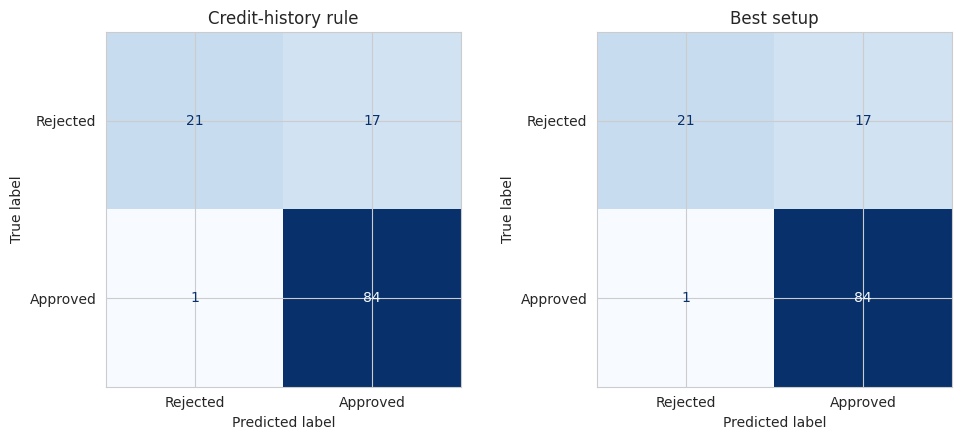

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (model, title) in zip(axes, [(rule_model, "Credit-history rule"), (best_model, "Best setup")]):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Rejected", "Approved"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

**How to read this:** The top-right cell of each matrix holds applications that were **rejected in reality but predicted as approved** (a bad loan would be given). The bottom-left cell holds applications that were **approved in reality but predicted as rejected** (a lost customer). Compare how these two numbers change between the simple rule and the best setup.

**Insight:** The four depth-1 setups tie at the top (CV balanced accuracy 0.689, accuracy 0.798), with or without the new features and class weights, so the simplest one is chosen. The new features do not help: with them, the best deeper tree scores 0.686, slightly below the plain depth-1 tree. Class weights catch more rejected applications (up to 0.535, against about 0.40) but approve fewer good ones (as low as 0.743, against 0.98), so balanced accuracy falls for every weighted setup.

## 9. Read the Tree

The big advantage of a decision tree is that you can **see exactly how it decides**. Below is the top of the final tree (up to 3 levels), followed by the same rules as text.

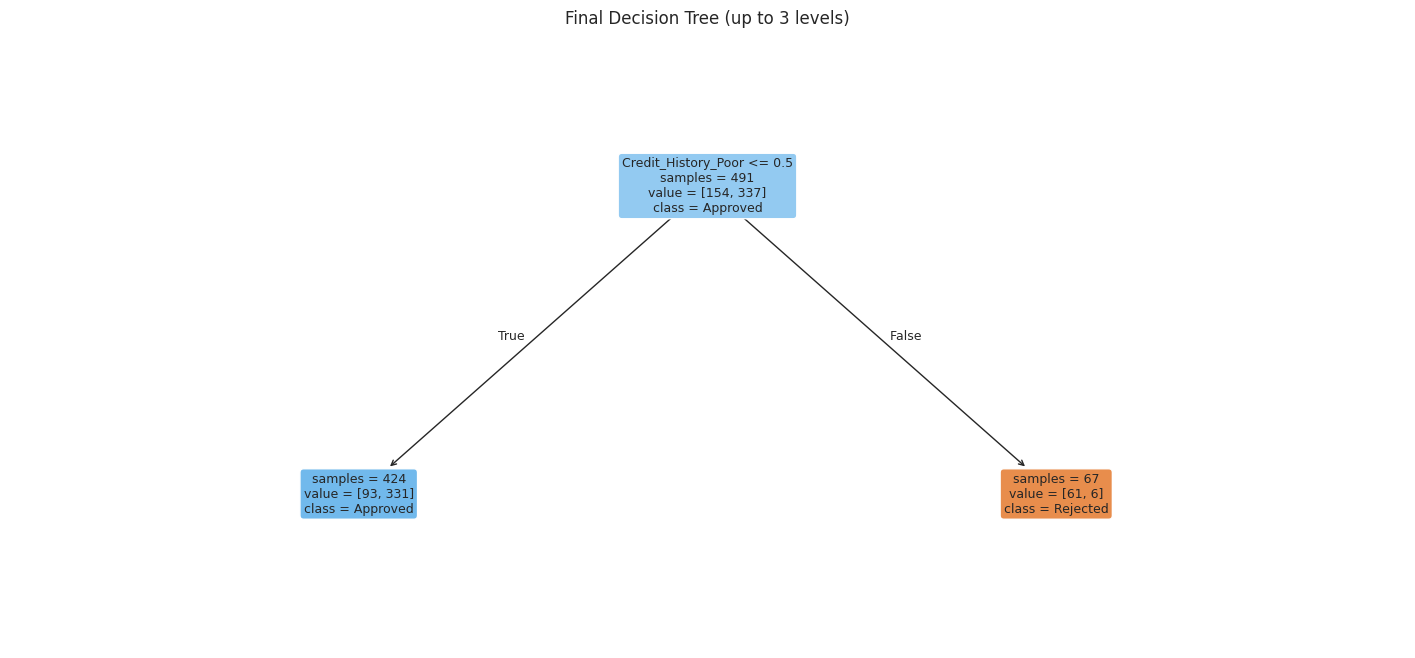

In [17]:
pre = best_model.named_steps["columntransformer"]
tree = best_model.named_steps["decisiontreeclassifier"]
feature_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=feature_names, class_names=["Rejected", "Approved"],
          filled=True, rounded=True, max_depth=3, fontsize=9, impurity=False)
plt.title("Final Decision Tree (up to 3 levels)")
plt.show()

In [18]:
print(export_text(tree, feature_names=feature_names, max_depth=3))

|--- Credit_History_Poor <= 0.50
|   |--- class: 1
|--- Credit_History_Poor >  0.50
|   |--- class: 0



**How to read this:** Each box shows the question (left branch = "yes", right branch = "no"), the number of training applications that reached it (`samples`), the weighted count of each class (`value`), and the predicted class. With class weights, the `value` numbers are weighted, so rejected applications count more than their raw number.

## 10. Which Features Matter Most?

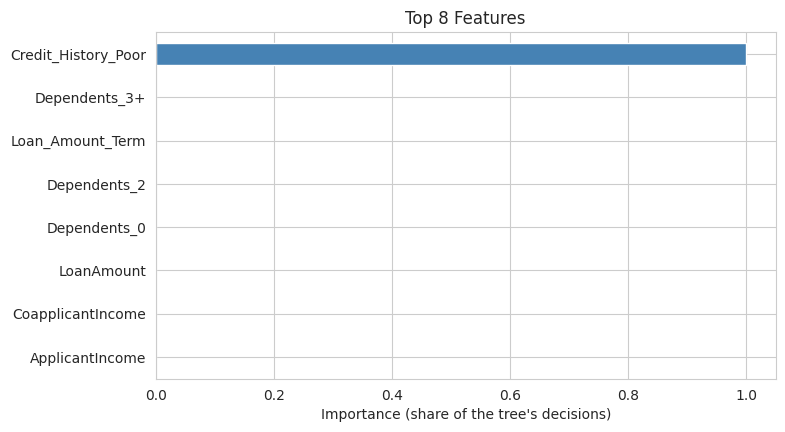

In [19]:
importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values(ascending=False)
top_imp = importances.head(8).sort_values()

plt.figure(figsize=(8, 4.5))
top_imp.plot(kind="barh", color="steelblue")
plt.xlabel("Importance (share of the tree's decisions)")
plt.title("Top 8 Features")
plt.show()

**Note:** Importance shows how much the tree relied on a feature. It does not prove cause and effect, and in a small dataset the importances can change a lot with a different split.

**Insight:** The final tree has a single question, so credit history is the only feature with any importance. That is also why the website's decision depends only on the credit history.

## 11. Example Prediction

With class weights, the tree's `predict_proba` is based on **weighted** counts, which is hard to interpret. So for the website, each leaf shows a simpler number: **the share of similar training applications that were approved**. The tree approves an application when this share is above a cut-off. Without class weights that cut-off is 50%. With balanced class weights it equals the overall approval rate of the training data, so the tree approves only when similar past applications were approved **more often than average**.

In [20]:
# Share of approved applications among the TRAINING applications that end in each leaf
Xt_train = pre.transform(X_train)
leaf_share = pd.Series(y_train.values).groupby(tree.apply(Xt_train)).mean()

# Cut-off above which the tree predicts "approved"
if best_weight == "balanced":
    n = len(y_train)
    n1 = int(y_train.sum())
    n0 = n - n1
    w1, w0 = n / (2 * n1), n / (2 * n0)
    approve_above = w0 / (w0 + w1)
else:
    approve_above = 0.5
print(f"The tree approves when the leaf approval share is above {approve_above * 100:.1f}%")


def approval_share(rows):
    return leaf_share.reindex(tree.apply(pre.transform(rows))).values


sample = X_test.iloc[[0]]
share = approval_share(sample)[0]
actual = "Approved" if y_test.iloc[0] == 1 else "Rejected"

print(sample.T)
print(f"\nShare of similar training applications that were approved: {share * 100:.1f}%")
print("Predicted:", "Approved" if share > approve_above else "Rejected")
print("Actual:   ", actual)

The tree approves when the leaf approval share is above 50.0%
                          150
ApplicantIncome          6277
CoapplicantIncome         0.0
LoanAmount              118.0
Loan_Amount_Term        360.0
TotalIncome            6277.0
EMI                327.777778
EMI_to_Income        0.052219
Dependents                  0
Education            Graduate
Self_Employed              No
Credit_History           Poor
Property_Area           Rural

Share of similar training applications that were approved: 9.0%
Predicted: Rejected
Actual:    Rejected


## 12. Export the Model for the Website

A decision tree is just a list of questions, so the whole tree is saved to `model.json`: for each node, which feature it checks, the threshold, and where to go next. The web page repeats the same steps in JavaScript and also shows the exact path the application followed. The new features (total income, instalment, instalment-to-income) are calculated in the page with the same formulas used in this notebook.

In [21]:
ohe = pre.named_transformers_["cat"].named_steps["onehotencoder"]
t = tree.tree_

best_test = test_report(best_model, "Best setup")

model_json = {
    "input_cols": BASE_NUM,
    "model_num_cols": best_num_cols,
    "cat_cols": CAT_COLS,
    "categories": [[str(v) for v in cats] for cats in ohe.categories_],
    "left": t.children_left.tolist(),
    "right": t.children_right.tolist(),
    "feature": t.feature.tolist(),
    "threshold": [float(v) for v in t.threshold],
    "prob": [round(float(leaf_share.get(i, 0.0)), 4) for i in range(t.node_count)],
    "approve_above": round(float(approve_above), 4),
    "ranges": {c: [float(np.floor(X_train[c].min())), float(np.ceil(X_train[c].max()))] for c in BASE_NUM},
    "defaults_num": {c: float(round(X_train[c].median())) for c in BASE_NUM},
    "defaults_cat": {c: str(X_train[c].mode()[0]) for c in CAT_COLS},
    "depth": int(tree.get_depth()),
    "class_weight": best["Class weight"],
    "test_accuracy": round(best_test["Accuracy"] * 100, 1),
    "test_rejected_caught": round(best_test["Rejected caught"] * 100, 1),
    "test_approved_found": round(best_test["Approved found"] * 100, 1),
}

with open("model.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"), ensure_ascii=False)

print("Tree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
print("model.json size: %.1f KB" % (os.path.getsize("model.json") / 1e3))

# Values for checking the website
# Use the first test application that has no missing values, so every field can be typed in
check_idx = X_test[BASE_NUM + CAT_COLS].dropna().index[0]
check = X_test.loc[check_idx, BASE_NUM + CAT_COLS]
check_share = approval_share(X_test.loc[[check_idx]])[0]
print("\nType these values into the website:")
for name, val in check.items():
    print(name, ":", val)
print("\nNotebook says: %s, %.1f%% of similar past applications were approved"
      % ("Approved" if check_share > approve_above else "Rejected", check_share * 100))

try:
    from google.colab import files
    files.download("model.json")
except ImportError:
    pass

Tree depth: 1 | leaves: 2
model.json size: 1.0 KB

Type these values into the website:
ApplicantIncome : 6277
CoapplicantIncome : 0.0
LoanAmount : 118.0
Loan_Amount_Term : 360.0
Dependents : 0
Education : Graduate
Self_Employed : No
Credit_History : Poor
Property_Area : Rural

Notebook says: Rejected, 9.0% of similar past applications were approved


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Results Summary

In [22]:
rule = comparison.iloc[1]
final = comparison.iloc[2]
print(f"Best setup: {best['Features']}, class weight {best['Class weight']}, depth {best_depth}")
print()
print(f"{'':32s}{'Rule':>10s}{'Best':>10s}")
print(f"{'Accuracy':32s}{rule['Accuracy']:>10.3f}{final['Accuracy']:>10.3f}")
print(f"{'Balanced accuracy':32s}{rule['Balanced accuracy']:>10.3f}{final['Balanced accuracy']:>10.3f}")
print(f"{'Rejected caught':32s}{rule['Rejected caught']:>10.3f}{final['Rejected caught']:>10.3f}")
print(f"{'Approved found':32s}{rule['Approved found']:>10.3f}{final['Approved found']:>10.3f}")
print(f"{'Bad loans wrongly approved':32s}{rule['Bad loans wrongly approved']:>10d}{final['Bad loans wrongly approved']:>10d}")
print(f"{'Good loans wrongly rejected':32s}{rule['Good loans wrongly rejected']:>10d}{final['Good loans wrongly rejected']:>10d}")
print("\nBaseline accuracy:", round(baseline_acc, 3))
print("Most important feature:", importances.index[0])

Best setup: Original, class weight none, depth 1

                                      Rule      Best
Accuracy                             0.854     0.854
Balanced accuracy                    0.770     0.770
Rejected caught                      0.553     0.553
Approved found                       0.988     0.988
Bad loans wrongly approved              17        17
Good loans wrongly rejected              1         1

Baseline accuracy: 0.691
Most important feature: Credit_History_Poor


## 14. Conclusion

The simplest tree was also the best one. A single question (is the credit history Poor?) reached 0.798 cross-validated accuracy, and deeper trees overfit: train accuracy rose from 0.798 to 0.857 while cross-validated accuracy fell to 0.709. Neither improvement beat it. The new features (total income, instalment, instalment-to-income) added nothing, and class weights caught more rejected applications (about 0.54 against 0.40) only by rejecting many more good ones, which lowered balanced accuracy. On the test set the tree reached 0.854 accuracy against a 0.691 baseline, but it still approved 17 of the 38 applications that should have been rejected. The data does not contain enough information beyond credit history to do much better. This is an educational example and must not be used for real lending decisions.

## 15. Limitations and Next Steps

**Limitations**
- The dataset is small (about 600 applications), so the test set is only about 120 applications, and the results can change a lot with a different split.
- Most of the predictive power comes from one feature (credit history), so the model is mostly a credit-history rule with a few refinements.
- The data comes from a single company at one point in time, and real lending decisions depend on many more factors.
- Class weights make the tree more cautious, but a wrongly rejected good applicant is also a real cost. The balance between the two mistakes is a business decision, not only a technical one.
- Gender and marital status were left out on purpose for fairness, but other features can still be correlated with them.
- The model is an educational example and must not be used to make real lending decisions.

**Next steps**
- Compare with Random Forest and Gradient Boosting on the same data
- Tune `min_samples_leaf` and the splitting criterion with `GridSearchCV`
- Put an explicit cost on each type of mistake and choose the setup that minimizes the total cost